# **PREVENDO VALORES DE VEÍCULOS**

## **Definindo o Problema de Negócio**

<p> Construir um modelo de Machile Learning que seja capaz de fazer previsões sobre o valor de venda de veículos, avaliando o melhor score apresentado.
<br> A variável a ser prevista é um valor numérico que representa o valor para venda ou compra de um veículo.
<br> Para resolver esse problema podemos utilizar Regressão Linear.


<b>Fonte dos dados</b> - kaggle - https://www.kaggle.com/datasets/athirags/car-data

<b>Informações sobre as variáveis:</b>    
<br>Car_Name: Nome do carro
<br>Year: Ano que o carro foi vendido
<br>Present_Price: Preço atual decidido
<br>Mks_Driven: Total de Km rodados
<br>Fuel_Type: Tipo de Combustível (Diesel ou Petrol(Gasolina))
<br>Seller Type: Tipo de Venda
<br>Transmission: Tipo de Cambio (Manual ou Automático)
<br>Owner: Dono
<br>Selling_Price: O preço pelo qual o carro foi comprado (Essa será nossa variável TARGET)

## **Import de Módulos**

In [1]:
# ----------------------- Bibliotecas Padrão -----------------------
import warnings
import datetime
# ----------------------- Base da Análise -----------------------

# Persistência de Modelos
import joblib 

# Manipulação de Dados e Visualização
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------- Machine Learning (Modelos e Divisão) -----------------------

# Algoritmo principal
from xgboost import XGBRegressor
# Treino e Teste
from sklearn.model_selection import train_test_split
# Ensemble dos modelos
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression

# ----------------------- Pré-processamento e Métricas -----------------------

# Métricas de Avaliação
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

# Pré-processamento (Normalização e Padronização)
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# ----------------------- Configurações Gerais -----------------------

# Configurações de Avisos 
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Configurações do Pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

## **Análise Exploratória**

### Exploração Inicial

In [2]:
''' 
Nesta etapa, será realizada a leitura do arquivo CSV contendo os dados dos veículos, utilizando a biblioteca Pandas. 
É importante destacar que, para facilitar o carregamento dos dados, o arquivo deve estar localizado no mesmo diretório do notebook ou script Python. 
Caso contrário, será necessário informar o caminho completo até o arquivo.

Em seguida, será conduzida uma Análise Exploratória (Exploratory Data Analysis — EDA), com o objetivo de compreender a estrutura e as características do conjunto de dados, 
bem como identificar possíveis inconsistências, valores ausentes, duplicidades e outros problemas relacionados à qualidade dos dados.

Com base nos resultados dessa análise inicial, será possível definir as estratégias de pré-processamento dos dados, contemplando etapas de limpeza, 
transformação e preparação das variáveis, de modo a garantir que os dados estejam adequados para o treinamento do modelo de Machine Learning.

Por fim, conforme estabelecido no enunciado do projeto, o objetivo consiste em prever o valor de venda dos veículos. 
Dessa forma, a variável target (alvo) será representada pela coluna correspondente ao preço de venda, 
enquanto as demais colunas do DataFrame serão consideradas features (variáveis preditoras), utilizadas pelo modelo para realizar as previsões.
'''

df = pd.read_csv('cardata.csv')
df.head(10)

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
5,vitara brezza,2018,9.25,9.83,2071,Diesel,Dealer,Manual,0
6,ciaz,2015,6.75,8.12,18796,Petrol,Dealer,Manual,0
7,s cross,2015,6.50,8.61,33429,Diesel,Dealer,Manual,0
8,ciaz,2016,8.75,8.89,20273,Diesel,Dealer,Manual,0
9,ciaz,2015,7.45,8.92,42367,Diesel,Dealer,Manual,0


In [3]:
df.shape

(301, 9)

In [4]:
df.tail()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
296,city,2016,9.50,11.6,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.9,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.0,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.5,9000,Diesel,Dealer,Manual,0
300,brio,2016,5.30,5.9,5464,Petrol,Dealer,Manual,0


### Análise estrutural e Qualidade dos dados

In [5]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 30.0 KB


In [7]:
df.isna().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

In [8]:
df.nunique()

Car_Name          98
Year              16
Selling_Price    156
Present_Price    147
Kms_Driven       206
Fuel_Type          3
Seller_Type        2
Transmission       2
Owner              3
dtype: int64

### Agrupamentos

In [9]:
'''
Nesta etapa, será realizada uma análise detalhada da distribuição das variáveis categóricas presentes no conjunto de dados. 
O objetivo é compreender a frequência e a diversidade de valores de cada variável, identificando as categorias existentes, 
sua representatividade e possíveis desequilíbrios na distribuição.

Essa análise permitirá identificar características relevantes do conjunto de dados, como categorias predominantes, valores pouco frequentes e possíveis inconsistências, 
contribuindo para uma melhor compreensão das variáveis e auxiliando na definição das estratégias de pré-processamento para as próximas etapas do projeto.
'''

df.groupby(['Fuel_Type']).size()

Fuel_Type
CNG         2
Diesel     60
Petrol    239
dtype: int64

In [10]:
df.groupby(['Seller_Type']).size()

Seller_Type
Dealer        195
Individual    106
dtype: int64

In [11]:
df.groupby(['Transmission']).size()

Transmission
Automatic     40
Manual       261
dtype: int64

In [12]:
df.groupby(['Owner']).size()

Owner
0    290
1     10
3      1
dtype: int64

In [13]:
df.groupby(['Selling_Price']).size().head()

Selling_Price
0.10    1
0.12    1
0.15    1
0.16    1
0.17    1
dtype: int64

### Boxplots

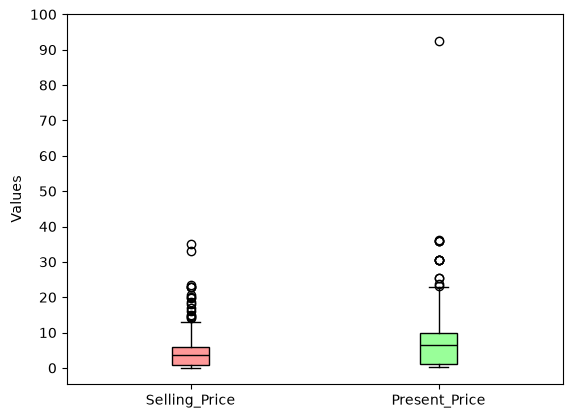

In [14]:
'''
Nesta etapa, será realizada uma análise visual da distribuição das variáveis numéricas presentes no conjunto de dados, utilizando gráficos de boxplot (diagramas de caixa). 
O principal objetivo é identificar a presença de possíveis outliers (valores discrepantes), que podem influenciar a análise dos dados e, dependendo do algoritmo utilizado, 
comprometer o desempenho do modelo de Machine Learning.

Além disso, a análise permitirá compreender melhor a dispersão dos dados, a mediana, os quartis e possíveis assimetrias nas distribuições das variáveis numéricas.

Essa etapa é importante para avaliar a qualidade dos dados e auxiliar na definição de estratégias de pré-processamento, 
como o tratamento de valores discrepantes e a aplicação de técnicas de normalização ou padronização, quando necessário, 
preparando as variáveis para as etapas posteriores de treinamento e avaliação do modelo.

'''

# Boxplot comparativo entre o Preço de Venda e o Preço Anunciado/Atual
bplot = plt.boxplot(
    df[['Selling_Price', 'Present_Price']], 
    patch_artist=True, medianprops=dict(color='black')
)

colors = ['#FF9999', '#99FF99']
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.xticks([1, 2], ['Selling_Price', 'Present_Price'])
plt.yticks(range(0, 105,10))
plt.ylabel('Values')
plt.show()

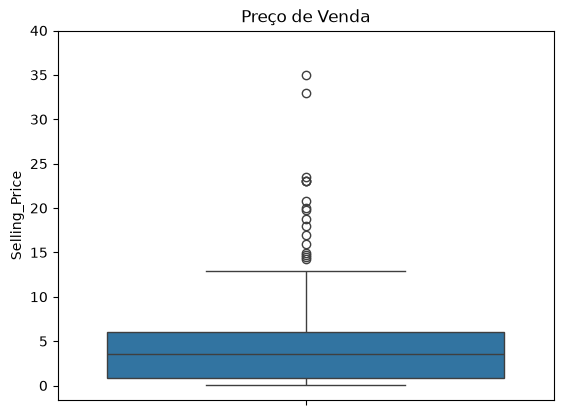

In [15]:
sns.boxplot(df['Selling_Price'])
plt.title('Preço de Venda')
plt.yticks(range(0, 45,5))
plt.show()

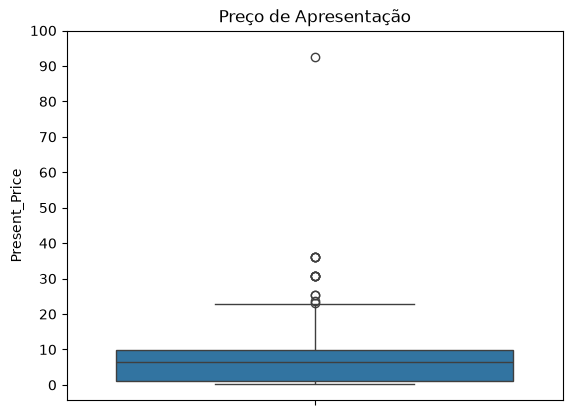

In [16]:
sns.boxplot(df['Present_Price'])
plt.title('Preço de Apresentação')
plt.yticks(range(0, 105,10))
plt.show()

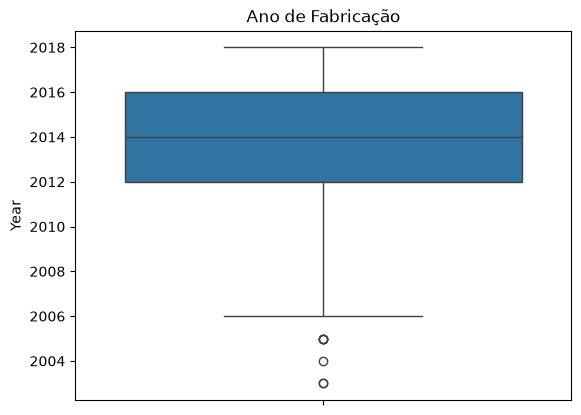

In [17]:
sns.boxplot(df['Year'])
plt.title('Ano de Fabricação')
plt.show()

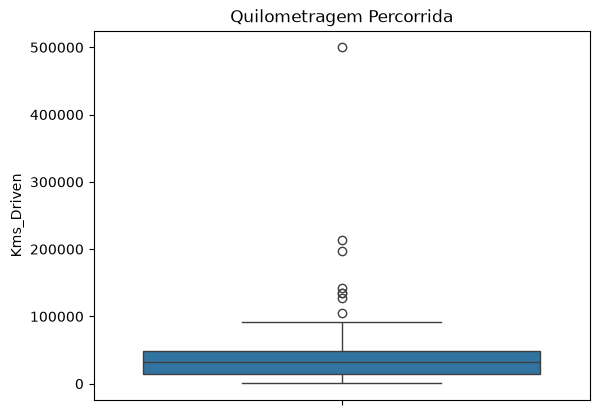

In [18]:
sns.boxplot(df['Kms_Driven'])
plt.title('Quilometragem Percorrida')
plt.show()

### Correlação

In [19]:
# Matriz de Correlação
df.corr(numeric_only=True)

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
Year,1.000000,0.236141,-0.047584,-0.524342,-0.182104
Selling_Price,0.236141,1.000000,0.878983,0.029187,-0.088344
Present_Price,-0.047584,0.878983,1.000000,0.203647,0.008057
Kms_Driven,-0.524342,0.029187,0.203647,1.000000,0.089216
Owner,-0.182104,-0.088344,0.008057,0.089216,1.000000


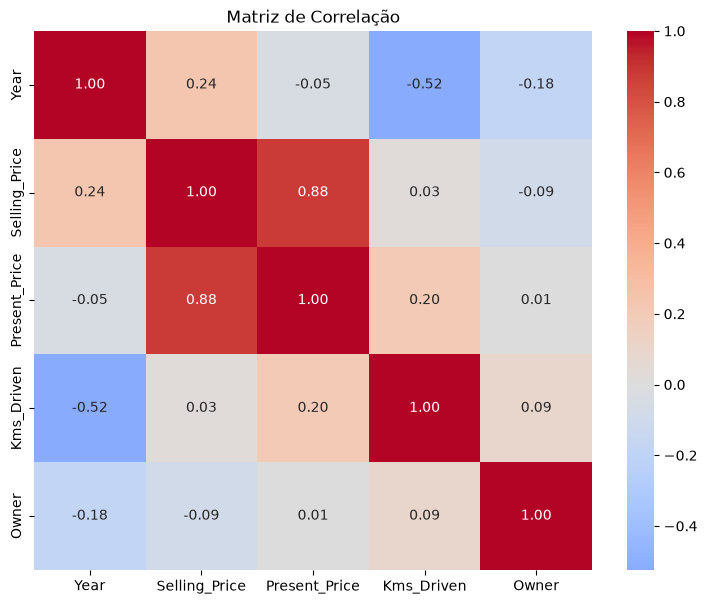

In [20]:
# Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de Correlação')
plt.show()

## **Pré Processamento / Tratamento**

### Feature Engineering

In [21]:
'''
Nesta etapa, será realizada a Engenharia de Atributos (Feature Engineering), com o objetivo de transformar e enriquecer o conjunto de dados, 
tornando as variáveis mais representativas e adequadas para o treinamento do modelo de Machine Learning.

Inicialmente, será criada uma nova variável denominada Age, que representará a idade dos veículos, calculada a partir do ano de fabricação ou modelo em relação ao ano de referência definido. 
Essa transformação permitirá substituir ou complementar a informação temporal original por uma característica que pode apresentar maior relevância para a previsão do preço de venda dos veículos.

Em seguida, será realizado o tratamento de possíveis outliers identificados nas variáveis numéricas. Para isso, será utilizada a abordagem baseada em ordenação dos valores (sorting), 
permitindo analisar a distribuição das observações e auxiliar na identificação e no tratamento de valores extremos, reduzindo possíveis impactos negativos no treinamento do modelo.

Por fim, será realizada a codificação das variáveis categóricas (Categorical Encoding), convertendo os atributos textuais em representações numéricas que possam ser interpretadas pelos algoritmos de Machine Learning. 
Essa transformação será conduzida de acordo com as características de cada variável, buscando preservar as informações relevantes e garantir a compatibilidade dos dados com os modelos preditivos.

Ao final dessa etapa, espera-se obter um conjunto de dados transformado, consistente e preparado para as próximas fases do projeto, especialmente a seleção de atributos e o treinamento dos modelos de regressão.'''

# Obter a data e hora atual
datahora = datetime.datetime.now()
print(f"Data e hora atual: {datahora.strftime('%Y-%m-%d %H:%M:%S')}")

Data e hora atual: 2026-11-25 02:15:54


In [22]:
# Verificar o ano atual    
ano_atual = datahora.year 

# Engenharia de Atributos: Criar uma nova coluna 'Age' com base no ano atual e no ano de fabricação do veículo
df['Age'] = ano_atual - df['Year'] 
df.head(10)

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12
5,vitara brezza,2018,9.25,9.83,2071,Diesel,Dealer,Manual,0,8
6,ciaz,2015,6.75,8.12,18796,Petrol,Dealer,Manual,0,11
7,s cross,2015,6.50,8.61,33429,Diesel,Dealer,Manual,0,11
8,ciaz,2016,8.75,8.89,20273,Diesel,Dealer,Manual,0,10
9,ciaz,2015,7.45,8.92,42367,Diesel,Dealer,Manual,0,11


In [23]:
# Excluir a coluna 'Year' do DataFrame, pois agora temos a coluna 'Age' que representa a idade do veículo
df.drop('Year', axis=1, inplace=True)
df.head(10)

,Car_Name,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age
0,ritz,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,4.60,6.87,42450,Diesel,Dealer,Manual,0,12
5,vitara brezza,9.25,9.83,2071,Diesel,Dealer,Manual,0,8
6,ciaz,6.75,8.12,18796,Petrol,Dealer,Manual,0,11
7,s cross,6.50,8.61,33429,Diesel,Dealer,Manual,0,11
8,ciaz,8.75,8.89,20273,Diesel,Dealer,Manual,0,10
9,ciaz,7.45,8.92,42367,Diesel,Dealer,Manual,0,11


### Tratamento de Outliers

In [24]:
# Ordenar os preços de venda em ordem decrescente para avaliar possíveis outliers vistos no boxplot
sorted(df['Selling_Price'],reverse=True)

[35.0,
 33.0,
 23.5,
 23.0,
 23.0,
 23.0,
 20.75,
 19.99,
 19.75,
 18.75,
 18.0,
 17.0,
 16.0,
 14.9,
 14.73,
 14.5,
 14.25,
 12.9,
 12.5,
 11.75,
 11.5,
 11.45,
 11.25,
 11.25,
 11.25,
 10.9,
 10.25,
 10.11,
 9.7,
 9.65,
 9.5,
 9.25,
 9.25,
 9.25,
 9.15,
 9.1,
 8.99,
 8.75,
 8.65,
 8.55,
 8.5,
 8.4,
 8.4,
 8.35,
 8.25,
 8.25,
 7.9,
 7.75,
 7.75,
 7.75,
 7.5,
 7.5,
 7.5,
 7.45,
 7.45,
 7.45,
 7.4,
 7.25,
 7.25,
 7.2,
 7.05,
 6.95,
 6.85,
 6.75,
 6.7,
 6.6,
 6.5,
 6.5,
 6.45,
 6.4,
 6.25,
 6.25,
 6.15,
 6.1,
 6.0,
 6.0,
 6.0,
 6.0,
 5.95,
 5.95,
 5.9,
 5.85,
 5.85,
 5.8,
 5.75,
 5.75,
 5.65,
 5.5,
 5.5,
 5.5,
 5.5,
 5.5,
 5.4,
 5.4,
 5.35,
 5.3,
 5.3,
 5.25,
 5.25,
 5.25,
 5.25,
 5.25,
 5.25,
 5.25,
 5.2,
 5.15,
 5.11,
 5.0,
 4.95,
 4.95,
 4.9,
 4.9,
 4.85,
 4.8,
 4.8,
 4.75,
 4.75,
 4.75,
 4.75,
 4.75,
 4.75,
 4.65,
 4.6,
 4.5,
 4.5,
 4.5,
 4.5,
 4.5,
 4.5,
 4.5,
 4.4,
 4.4,
 4.4,
 4.35,
 4.15,
 4.1,
 4.1,
 4.0,
 4.0,
 4.0,
 4.0,
 4.0,
 3.95,
 3.95,
 3.9,
 3.9,
 3.8,
 3.75,
 3.75,
 3.6

In [25]:
# Avaliar os registros com preços de venda acima de 33.0, que podem ser considerados outliers
df[(df['Selling_Price'] >= 33.0)]

,Car_Name,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age
64,fortuner,33.0,36.23,6000,Diesel,Dealer,Automatic,0,9
86,land cruiser,35.0,92.60,78000,Diesel,Dealer,Manual,0,16


In [26]:
# Filtrar os registros com preços de venda menores que 33.0
df[(df['Selling_Price'] < 33.0)]

#df[~(df['Selling_Price'] >= 33.0)] forma alternativa de filtrar

,Car_Name,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age
0,ritz,3.35,5.590,27000,Petrol,Dealer,Manual,0,12
1,sx4,4.75,9.540,43000,Diesel,Dealer,Manual,0,13
2,ciaz,7.25,9.850,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2.85,4.150,5200,Petrol,Dealer,Manual,0,15
4,swift,4.60,6.870,42450,Diesel,Dealer,Manual,0,12
5,vitara brezza,9.25,9.830,2071,Diesel,Dealer,Manual,0,8
6,ciaz,6.75,8.120,18796,Petrol,Dealer,Manual,0,11
7,s cross,6.50,8.610,33429,Diesel,Dealer,Manual,0,11
8,ciaz,8.75,8.890,20273,Diesel,Dealer,Manual,0,10
9,ciaz,7.45,8.920,42367,Diesel,Dealer,Manual,0,11


In [27]:
# Atualizar o DataFrame com os registros com preços de venda menores que 33.0
df = df[(df['Selling_Price'] < 33.0)]
df.shape

(299, 9)

### Encoding

In [28]:
'''
Vamos aplicar encoding nas variáveis categóricas do DataFrame, 
transformando-as em variáveis numéricas para que possam ser utilizadas nos modelos de machine learning.
'''

df['Fuel_Type'].unique()

<ArrowStringArray>
['Petrol', 'Diesel', 'CNG']
Length: 3, dtype: str

In [29]:
# Aplicando o Encoding utilizando a função map
df['Fuel_Type'] = df['Fuel_Type'].map({'Petrol': 0, 'Diesel': 1, 'CNG': 2})

# Checar os valores únicos da coluna 'Fuel_Type' após o encoding
df['Fuel_Type'].unique()

array([0, 1, 2])

In [30]:
# Visualizar os valores únicos da coluna 'Seller_Type' antes do encoding
df['Seller_Type'].unique()

<ArrowStringArray>
['Dealer', 'Individual']
Length: 2, dtype: str

In [31]:
# Aplicar o Encoding na coluna 'Fuel_Type'
df['Seller_Type'] = df['Seller_Type'].map({'Dealer': 0, 'Individual': 1})

# Checar os valores únicos da coluna 'Seller_Type' após o encoding
df['Seller_Type'].unique()

array([0, 1])

In [32]:
# Visualização dos valores unicos da coluna 'Transmission' antes do encoding
df['Transmission'].unique()

<ArrowStringArray>
['Manual', 'Automatic']
Length: 2, dtype: str

In [33]:
# Encoding da coluna 'Transmission' 
df['Transmission'] = df['Transmission'].map({'Manual': 0, 'Automatic': 1})

In [34]:
# Checar o DataFrame após a aplicação do encoding nas variáveis categóricas
df.head(10)

,Car_Name,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age
0,ritz,3.35,5.59,27000,0,0,0,0,12
1,sx4,4.75,9.54,43000,1,0,0,0,13
2,ciaz,7.25,9.85,6900,0,0,0,0,9
3,wagon r,2.85,4.15,5200,0,0,0,0,15
4,swift,4.60,6.87,42450,1,0,0,0,12
5,vitara brezza,9.25,9.83,2071,1,0,0,0,8
6,ciaz,6.75,8.12,18796,0,0,0,0,11
7,s cross,6.50,8.61,33429,1,0,0,0,11
8,ciaz,8.75,8.89,20273,1,0,0,0,10
9,ciaz,7.45,8.92,42367,1,0,0,0,11


### Seleção de Variáveis Preditoras e Target

In [35]:
# Excluindo as variáveis que não serão utilizadas no modelo de machine learning, como 'Car_Name' e 'Selling_Price', que é a variável alvo.
X = df.drop(['Car_Name', 'Selling_Price'], axis=1) 

# Variável alvo (target) que queremos prever, que é o preço de venda do veículo.
y = df['Selling_Price']

In [36]:
# Checagem do DataFrame x após a exclusão das variáveis 'Car_Name' e 'Selling_Price'
X.head()

,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Age
0,5.59,27000,0,0,0,0,12
1,9.54,43000,1,0,0,0,13
2,9.85,6900,0,0,0,0,9
3,4.15,5200,0,0,0,0,15
4,6.87,42450,1,0,0,0,12


In [37]:
# Checagem do DataFrame y, que é a variável alvo (target) que queremos prever, que é o preço de venda do veículo.
y.head()

0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64

In [38]:
# Quantidade de observações e Variáveis do DataFrame x
print(f"Quantidade de observações de variáveis preditoras: {X.shape[0]}")
print(f"Quantidade de observações da variável alvo: {y.shape[0]}")

Quantidade de observações de variáveis preditoras: 299
Quantidade de observações da variável alvo: 299


## **Construção do Modelo Preditivo**

### **Separação dos Dados de Treino e Teste**

In [39]:
'''
Nesta etapa, será realizada a divisão do conjunto de dados em subconjuntos de treinamento (x_train e y_train) e teste (x_test e y_test), 
utilizando a função train_test_split, disponibilizada pela biblioteca Scikit-learn.

O objetivo dessa divisão é separar os dados que serão utilizados no treinamento do modelo daqueles reservados para sua avaliação. Dessa forma, 
o modelo será treinado utilizando uma parcela dos dados e posteriormente avaliado com observações que não foram utilizadas durante o treinamento, 
permitindo verificar sua capacidade de generalização e avaliar o seu desempenho.

Para essa divisão, serão utilizados os seguintes parâmetros:

- test_size: Define a proporção do conjunto de dados destinada ao teste. Neste projeto, será utilizado o valor de 0.25, 
correspondente a 25% dos dados para teste e 75% para treinamento.
- random_state: Define uma semente aleatória para garantir a reprodutibilidade da divisão dos dados (parâmetro opcional).
Neste caso, será utilizado o valor 42 como semente, garantindo que a divisão seja reproduzível, 
desde que os dados de entrada e as demais condições permaneçam iguais.

Após a aplicação da função, serão obtidos os seguintes conjuntos:

x_train: Conjunto de treino das variáveis preditoras (features), composto por 75% dos dados.
x_test: Conjunto de teste das variáveis preditoras (features), composto por 25% dos dados.
y_train: Conjunto de treino da variável alvo (target), composto por 75% dos dados.
y_test: Conjunto de teste da variável alvo (target), composto por 25% dos dados.

Esses subconjuntos serão utilizados na próxima etapa do projeto, na qual será realizado o treinamento do modelo de regressão utilizando o algoritmo XGBoost,
baseado em árvores de decisão, seguido da avaliação de seu desempenho.
'''

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

### **Convenção de Nomenclatura (`X` vs. `y`)**

Por padrão da álgebra linear e da biblioteca `scikit-learn`, diferenciamos a estrutura dos dados pelo tamanho da letra:

* **`X` (Maiúsculo):** Representa uma **matriz** (estrutura bidimensional com linhas e múltiplas colunas/features).
* **`y` (Minúsculo):** Representa um **vetor** (estrutura unidimensional contendo apenas a coluna alvo a ser prevista).

In [40]:
print(f"Quantidade de observações de variáveis preditoras do conjunto de treino: {X_train.shape[0]}")
print(f"Quantidade de observações de variáveis preditoras do conjunto de teste: {X_test.shape[0]}")
print(f"Quantidade de observações da variável alvo do conjunto de treino: {y_train.shape[0]}")
print(f"Quantidade de observações da variável alvo do conjunto de teste: {y_test.shape[0]}")

Quantidade de observações de variáveis preditoras do conjunto de treino: 224
Quantidade de observações de variáveis preditoras do conjunto de teste: 75
Quantidade de observações da variável alvo do conjunto de treino: 224
Quantidade de observações da variável alvo do conjunto de teste: 75


### **Escolha do algoritmo, Criação e Treino do Modelo**

Serão aplicados quatro algoritmos de regressão, com o objetivo de comparar seus desempenhos e identificar aquele que apresenta os melhores resultados para o problema em questão.


Serão utilizados **quatro algoritmos de regressão** para realizar uma análise comparativa de desempenho, com o objetivo de identificar qual deles apresenta os melhores resultados para o problema em questão.

O processo será dividido nas seguintes etapas:

1. **Treinamento dos modelos:** cada algoritmo será treinado utilizando os mesmos conjuntos de dados, garantindo condições equivalentes de comparação.

2. **Avaliação de desempenho:** serão utilizadas métricas de avaliação para analisar a qualidade das previsões realizadas por cada modelo.

3. **Comparação dos resultados:** os desempenhos serão comparados considerando aspectos como:
   - Precisão das previsões;
   - Capacidade de generalização;
   - Erros apresentados nas estimativas;
   - Desempenho geral do modelo.

4. **Seleção do melhor modelo:** com base nos resultados obtidos, será selecionado o algoritmo que apresentar o desempenho mais adequado às características e necessidades específicas do problema.

**Objetivo final:** identificar o modelo de regressão mais eficiente e confiável para a tarefa de previsão proposta.

In [41]:
"""
Implementa os modelos de regressão Linear Regression, Random Forest, Gradient Boosting e XGBoost, que serão utilizados na análise comparativa
para a identificação do modelo mais adequado ao problema de previsão.
"""

# Instanciação e treinamento do modelo de Regressão Linear
lr = LinearRegression()  # Não tem aleatoriedade
lr.fit(X_train, y_train)

# Instanciação e treinamento do modelo Random Forest
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

# Instanciação e treinamento do modelo Gradient Boosting
gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)

# Instanciação e treinamento do modelo XGBoost
xgb = XGBRegressor(random_state=42)
xgb.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### **Geração de Previsões (Inferência)**

Nesta etapa, aplicamos os quatro algoritmos previamente treinados (`Linear Regression`, `Random Forest`, `Gradient Boosting` e `XGBoost`) sobre o conjunto de dados de teste (`x_test`). 

O objetivo é gerar as estimativas de cada modelo de forma padronizada para que possamos comparar seus erros e identificar qual abordagem generaliza melhor para dados inéditos.

In [42]:
"""Executa a etapa de inferência no conjunto de teste (`X_test`) para os quatro modelos previamente treinados (`lr`, `rf`, `gb` e `xgb`), 
armazenando as estimativas resultantes de cada algoritmo para avaliação comparativa.
"""

pred_lr = lr.predict(X_test)
pred_rf = rf.predict(X_test)
pred_gb = gb.predict(X_test)
pred_xgb = xgb.predict(X_test)

In [43]:
pred_lr

array([ 8.28278028,  7.4327484 ,  1.34959496,  6.47486452, 12.47240402,
        4.42231142, 10.08337821,  1.78036592,  8.55652586, -1.2006253 ,
       11.70079826, -0.94663275, -0.14283369,  1.38549397,  9.83399181,
       10.91065926,  1.19275284,  1.990915  , 22.95723494,  0.76060948,
        0.86152762,  2.84299003,  5.67135223,  2.40639559,  2.40380555,
        8.84051307,  8.8347934 ,  1.18262436,  5.25541299,  5.13843666,
        7.85615747,  5.40967132,  6.74897474,  2.25202653,  8.35832457,
        6.44236986,  1.32559172, -8.76078087,  1.27903097, 11.71340266,
        8.05464548,  9.22587703,  1.68927992,  3.62952265,  0.93383064,
       -2.10894596,  9.11459453,  4.35185189,  4.68702363, -0.82262876,
        0.67575946,  0.20825226, 12.236819  ,  9.63226226,  8.24287125,
        5.50825999,  3.734612  ,  2.63625152,  9.91717564, 22.76908528,
        5.65875725, -0.34750726, -0.06260966, -0.89486744,  3.72114579,
        4.5256544 ,  8.66229626,  4.79182538,  2.53266326,  5.48

In [44]:
pred_rf

array([10.2042,  8.129 ,  0.4357,  6.8895, 13.7475,  5.285 ,  6.8175,
        1.1915,  8.004 ,  0.316 , 11.581 ,  0.2038,  0.247 ,  0.4566,
        4.7648,  7.234 ,  0.6007,  1.177 , 21.9275,  0.5559,  0.5614,
        2.4675,  6.2185,  2.945 ,  2.434 ,  9.3396,  8.776 ,  1.1485,
        4.8288,  5.3438,  7.7695,  4.434 ,  6.9145,  2.9075,  8.5163,
        6.3525,  1.1705,  0.1567,  1.1455, 12.995 ,  7.4356,  9.1214,
        0.8999,  3.4922,  0.5644,  0.209 ,  9.834 ,  4.9365,  3.9826,
        0.2316,  0.5978,  0.3323, 13.633 ,  9.901 ,  7.8898,  6.924 ,
        3.246 ,  2.828 , 10.153 , 20.7665,  6.416 ,  0.3593,  0.2853,
        0.4212,  3.278 ,  2.9225,  9.3535,  4.496 ,  2.914 ,  4.9165,
        0.7815,  5.3492,  6.892 ,  8.4692,  0.4711])

In [45]:
pred_gb

array([ 9.00822835,  8.64896927,  0.50152715,  7.16937971, 10.60002644,
        4.83291485,  6.20701675,  1.24621375,  8.46867441,  0.49490727,
        9.08544057,  0.19053052,  0.30782999,  0.54581373,  5.69040703,
        7.48085301,  0.62297215,  1.46391008, 21.37925973,  0.43961997,
        0.51638347,  2.92659693,  5.89260292,  3.17768661,  2.5590835 ,
        8.94870628,  9.90760257,  1.06739498,  4.76331456,  4.92245168,
        7.79295931,  4.47415449,  6.7675291 ,  2.71437944,  7.87726067,
        6.49319491,  1.13851162,  0.11437566,  1.06575504,  8.88533029,
        6.9195591 ,  9.3911703 ,  0.9071901 ,  3.541864  ,  0.54255136,
        0.19814791,  9.71379649,  4.45087642,  3.99362443,  0.21624977,
        0.53981684,  0.31449198,  8.79352527, 11.17887495,  8.23131467,
        6.95056688,  3.4743416 ,  2.71338904, 12.90203238, 19.80667758,
        6.73544895,  0.37526821,  0.27287853,  0.40597456,  3.47083873,
        3.08253492,  9.40532132,  4.46405796,  2.74326829,  4.68

In [46]:
pred_xgb

array([ 9.872594  ,  8.736616  ,  0.43426073,  7.0851126 , 10.577909  ,
        5.249046  ,  6.4713507 ,  1.2846173 ,  7.9020653 ,  0.28867725,
        9.350536  ,  0.23063433,  0.273173  ,  0.4327215 ,  4.9183073 ,
        7.168832  ,  0.63252544,  1.6783333 , 18.810719  ,  0.3639122 ,
        0.54363036,  1.3766756 ,  5.7287903 ,  2.9317951 ,  2.33132   ,
        9.133402  ,  8.74428   ,  1.0877929 ,  4.7220373 ,  5.1416407 ,
        7.759017  ,  3.9250464 ,  6.5938673 ,  2.3199859 ,  6.5538015 ,
        5.947032  ,  1.1404628 ,  0.15616448,  0.7267851 ,  8.725867  ,
        5.674859  ,  9.387238  ,  0.9283276 ,  3.7244139 ,  0.5020527 ,
        0.16577499, 10.2771    ,  4.6775894 ,  3.884433  ,  0.26816753,
        0.5585904 ,  0.372262  , 10.477427  , 10.528948  ,  5.862964  ,
        6.7667365 ,  3.394586  ,  2.7200377 , 11.598327  , 18.745384  ,
        6.307808  ,  0.26374128,  0.24767748,  0.39932987,  3.059431  ,
        2.9096043 ,  9.729754  ,  4.514561  ,  2.818545  ,  4.49

### **Avaliação da Performance dos Algoritmos**

In [47]:
mae_lr = mean_absolute_error(y_test, pred_lr)
mae_rf = mean_absolute_error(y_test, pred_rf)
mae_gb = mean_absolute_error(y_test, pred_gb)
mae_xgb = mean_absolute_error(y_test, pred_xgb)

print(f'Erro Médio Absoluto utilizando Linear Regression: {mae_lr}')
print(f'Erro Médio Absoluto utilizando Random Forest Regressor : {mae_rf}')
print(f'Erro Médio Absoluto utilizando Gadient Boosting Regressor: {mae_gb}')
print(f'Erro Médio Absoluto utilizando XGBoost Regressor : {mae_xgb}')

Erro Médio Absoluto utilizando Linear Regression: 1.3939060367976748
Erro Médio Absoluto utilizando Random Forest Regressor : 0.9406026666666681
Erro Médio Absoluto utilizando Gadient Boosting Regressor: 0.726046596887861
Erro Médio Absoluto utilizando XGBoost Regressor : 0.745981129582723


In [48]:
mape_lr = mean_absolute_percentage_error(y_test, pred_lr)
mape_rf = mean_absolute_percentage_error(y_test, pred_rf)
mape_gb = mean_absolute_percentage_error(y_test, pred_gb)
mape_xgb = mean_absolute_percentage_error(y_test, pred_xgb)

print(f'Erro Percentual Absoluto Médio utilizando Linear Regression: {mape_lr}')
print(f'Erro Percentual Absoluto Médio utilizando Random Forest Regressor : {mape_rf}')
print(f'Erro Percentual Absoluto Médio Gadient Boosting Regressor: {mape_gb}')
print(f'Erro Percentual Absoluto Médio XGBoost Regressor : {mape_xgb}')

Erro Percentual Absoluto Médio utilizando Linear Regression: 1.6425161337063947
Erro Percentual Absoluto Médio utilizando Random Forest Regressor : 0.26560861945676306
Erro Percentual Absoluto Médio Gadient Boosting Regressor: 0.2305069356936294
Erro Percentual Absoluto Médio XGBoost Regressor : 0.21608198508489102


In [49]:
score_lr = r2_score(y_test, pred_lr)
score_rf = r2_score(y_test, pred_rf)
score_gb = r2_score(y_test, pred_gb)
score_xgb = r2_score(y_test, pred_xgb)

print(f'Score utilizando Linear Regression: {score_lr}')
print(f'Score utilizando Random Forest Regressor : {score_rf}')
print(f'Score utilizando Gadient Boosting Regressor: {score_gb}')
print(f'Score utilizando XGBoost Regressor : {score_xgb}')

Score utilizando Linear Regression: 0.7106971141598667
Score utilizando Random Forest Regressor : 0.7745267171499192
Score utilizando Gadient Boosting Regressor: 0.9049447786945746
Score utilizando XGBoost Regressor : 0.8821570627049665


In [50]:
final_df = pd.DataFrame({
    'Models': ['LR', 'RF', 'GB', 'XGB'],
    'MAE': [mae_lr, mae_rf, mae_gb, mae_xgb],
    'MAPE': [mape_lr, mape_rf, mape_gb, mape_xgb],
    'R2_Score': [score_lr, score_rf, score_gb, score_xgb]
    })

final_df

,Models,MAE,MAPE,R2_Score
0,LR,1.393906,1.642516,0.710697
1,RF,0.940603,0.265609,0.774527
2,GB,0.726047,0.230507,0.904945
3,XGB,0.745981,0.216082,0.882157


## 📊 Avaliação e Comparação dos Modelos

Para avaliar o desempenho dos algoritmos de regressão no conjunto de teste (`y_test`), utilizamos três métricas complementares:

* **MAE (Erro Médio Absoluto):** Mede o erro médio na mesma unidade de medida da variável alvo. **Quanto menor, melhor** (`0` = acerto perfeito).
* **MAPE (Erro Percentual Absoluto Médio):** Mede o erro médio em termos percentuais em relação ao valor real. **Quanto menor, melhor** (`0%` = acerto perfeito).
* **R² (Coeficiente de Determinação):** Indica o quanto o modelo consegue explicar da variação dos dados. **Quanto maior, melhor** (`1.0` ou `100%` = explicação perfeita).

### Resultados Obtidos

| Modelo | MAE ↓ | MAPE (%) ↓ | R² Score ↑ | Desempenho Geral |
| :--- | :---: | :---: | :---: | :--- |
| **Gradient Boosting (GB)** | **0.7260** | 23.05% | **0.9049** | 🏆 **Melhor desempenho geral** (menor erro absoluto e maior R²) |
| **XGBoost (XGB)** | 0.7459 | **21.60%** | 0.8821 | 🥈 **2º lugar** (melhor equilíbrio percentual nos valores baixos) |
| **Random Forest (RF)** | 0.9406 | 26.56% | 0.7745 | 🥉 **3º lugar** (bom ajuste, mas erro ~28% maior que o líder) |
| **Linear Regression (LR)** | 1.3939 | 164.25% | 0.7106 | ⚠️ **Baseline** (dificuldade em capturar relações não lineares) |

### Principais Conclusões

1. **Superioridade dos modelos de Boosting.** O *Gradient Boosting* reduziu o erro médio absoluto em **47,9%** em relação ao baseline linear (`1.3939` → `0.7260`) e elevou o poder explicativo de `0.7107` para `0.9049`. A diferença é grande o bastante para confirmar que a relação entre os atributos e o preço de venda é predominantemente **não linear** — o que é esperado, já que a desvalorização de um veículo não é proporcional nem à idade nem à quilometragem.

2. **MAE e MAPE discordam entre GB e XGB — e isso é informação, não contradição.** O GB vence no MAE (`0.7260` vs `0.7460`) e no R² (`0.9049` vs `0.8822`), mas o XGB vence no MAPE (`21.61%` vs `23.05%`). O motivo é o denominador: o MAPE divide o erro pelo valor real, então errar `0.3` em um carro de `0.5` pesa mais do que errar `2.0` em um carro de `30.0`. Em outras palavras, **o GB é mais preciso em valor absoluto** (métrica dominada pelos veículos caros) e **o XGB é mais preciso em termos proporcionais** (métrica dominada pelos veículos baratos). A escolha entre eles não é técnica, é de negócio: depende de o prejuízo ser medido em reais ou em percentual do preço.

3. **O MAPE de 164% da Regressão Linear revela o modo de falha do modelo linear.** O erro não está distribuído: um modelo linear ajustado em uma base com `Selling_Price` entre `0.10` e `33.00` é forçado a usar uma única inclinação para toda a faixa, e consequentemente **superestima pesadamente os veículos mais baratos**. Como esses registros têm denominador próximo de zero, o erro percentual explode. O R² de `0.7107` esconde isso completamente, porque penaliza o erro ao quadrado e por isso é dominado pelos veículos caros, onde o ajuste linear é razoável. **Duas métricas sobre o mesmo modelo contando histórias opostas é exatamente o motivo para nunca avaliar com uma métrica só.**

4. **Modelo final: Gradient Boosting Regressor** (`MAE = 0.7260`, `MAPE = 23.05%`, `R² = 0.9049`), por liderar duas das três métricas, mantendo o XGBoost como alternativa imediata caso o critério de negócio passe a ser o erro relativo.


### **Aplicando Normalização nos Dados**

Etapa destinada à adequação das escalas das variáveis numéricas, reduzindo diferenças de magnitude entre os atributos e evitando que variáveis com valores absolutos maiores tenham influência desproporcional no processo de aprendizagem do modelo.

A normalização utiliza os parâmetros ajustados sobre o conjunto de treinamento, mantendo o mesmo padrão de transformação para os dados de teste.

Saída: Conjuntos de dados transformados e parâmetros de normalização preservados para uso nas etapas de treinamento e inferência.

In [51]:

"""
Aplicação da normalização Min-Max às variáveis numéricas,
reescalando os dados para o intervalo entre 0 e 1.

Os parâmetros são ajustados com base no conjunto de
treinamento e reutilizados na transformação do teste.
"""

# Aplicando Normalização
sc = MinMaxScaler()
X_train_norm = sc.fit_transform(X_train)
X_test_norm = sc.transform(X_test)

In [52]:
# Instanciação e treinamento do modelo de Regressão Linear
lr = LinearRegression()
lr.fit(X_train_norm, y_train)

# Instanciação e treinamento do modelo Random Forest
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train_norm, y_train)

# Instanciação e treinamento do modelo Gradient Boosting
gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train_norm, y_train)

# Instanciação e treinamento do modelo XGBoost
xgb = XGBRegressor(random_state=42)
xgb.fit(X_train_norm, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [53]:
pred_lr_norm = lr.predict(X_test_norm)
pred_rf_norm = rf.predict(X_test_norm)
pred_gb_norm = gb.predict(X_test_norm)
pred_xgb_norm = xgb.predict(X_test_norm)

In [54]:
# Erro médio absoluto
mae_lr_norm = mean_absolute_error(y_test, pred_lr_norm)
mae_rf_norm = mean_absolute_error(y_test, pred_rf_norm)
mae_gb_norm = mean_absolute_error(y_test, pred_gb_norm)
mae_xgb_norm = mean_absolute_error(y_test, pred_xgb_norm)

# Erro Percentual Absoluto Médio
mape_lr_norm = mean_absolute_percentage_error(y_test, pred_lr_norm)
mape_rf_norm = mean_absolute_percentage_error(y_test, pred_rf_norm)
mape_gb_norm = mean_absolute_percentage_error(y_test, pred_gb_norm)
mape_xgb_norm = mean_absolute_percentage_error(y_test, pred_xgb_norm)

# R² Score
score_lr_norm = r2_score(y_test, pred_lr_norm)
score_rf_norm = r2_score(y_test, pred_rf_norm)
score_gb_norm = r2_score(y_test, pred_gb_norm)
score_xgb_norm = r2_score(y_test, pred_xgb_norm)

In [55]:
final_df_norm = pd.DataFrame({
    'Models': ['LR', 'RF', 'GB', 'XGB'], 
    'MAE': [mae_lr_norm, mae_rf_norm, mae_gb_norm, mae_xgb_norm],
    'MAPE': [mape_lr_norm, mape_rf_norm, mape_gb_norm, mape_xgb_norm],
    'R2_Score': [score_lr_norm, score_rf_norm, score_gb_norm, score_xgb_norm]
    })
final_df_norm

,Models,MAE,MAPE,R2_Score
0,LR,1.393906,1.642516,0.710697
1,RF,0.935523,0.263089,0.774895
2,GB,0.726094,0.230903,0.904944
3,XGB,0.745981,0.216082,0.882157


### **Padronização para Comparação de Resultados**

In [56]:
ss = StandardScaler()
X_train_std = ss.fit_transform(X_train)
X_test_std = ss.transform(X_test)

In [57]:
# Instanciação e treinamento do modelo de Regressão Linear
lr = LinearRegression()
lr.fit(X_train_std, y_train)

# Instanciação e treinamento do modelo Random Forest
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train_std, y_train)

# Instanciação e treinamento do modelo Gradient Boosting
gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train_std, y_train)

# Instanciação e treinamento do modelo XGBoost
xgb = XGBRegressor(random_state=42)
xgb.fit(X_train_std, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [58]:
pred_lr_std = lr.predict(X_test_std)
pred_rf_std = rf.predict(X_test_std)
pred_gb_std = gb.predict(X_test_std)
pred_xgb_std = xgb.predict(X_test_std)

In [59]:
# Erro médio absoluto
mae_lr_std = mean_absolute_error(y_test, pred_lr_std)
mae_rf_std = mean_absolute_error(y_test, pred_rf_std)
mae_gb_std = mean_absolute_error(y_test, pred_gb_std)
mae_xgb_std = mean_absolute_error(y_test, pred_xgb_std)

# Erro Percentual Absoluto Médio
mape_lr_std = mean_absolute_percentage_error(y_test, pred_lr_std)
mape_rf_std = mean_absolute_percentage_error(y_test, pred_rf_std)
mape_gb_std = mean_absolute_percentage_error(y_test, pred_gb_std)
mape_xgb_std = mean_absolute_percentage_error(y_test, pred_xgb_std)

# R² Score
score_lr_std = r2_score(y_test, pred_lr_std)
score_rf_std = r2_score(y_test, pred_rf_std)
score_gb_std = r2_score(y_test, pred_gb_std)
score_xgb_std = r2_score(y_test, pred_xgb_std)

In [60]:
final_df_std = pd.DataFrame({
    'Models': ['LR', 'RF', 'GB', 'XGB'], 
    'MAE': [mae_lr_std, mae_rf_std, mae_gb_std, mae_xgb_std],
    'MAPE': [mape_lr_std, mape_rf_std, mape_gb_std, mape_xgb_std],
    'R2_Score': [score_lr_std, score_rf_std, score_gb_std, score_xgb_std]
    })

final_df_std

,Models,MAE,MAPE,R2_Score
0,LR,1.393906,1.642516,0.710697
1,RF,0.936864,0.264419,0.774825
2,GB,0.726309,0.230682,0.904891
3,XGB,0.745981,0.216082,0.882157


### **Visualização das Métricas**

#### **Plotagem sem transformação de escala**

<Figure size 800x600 with 0 Axes>

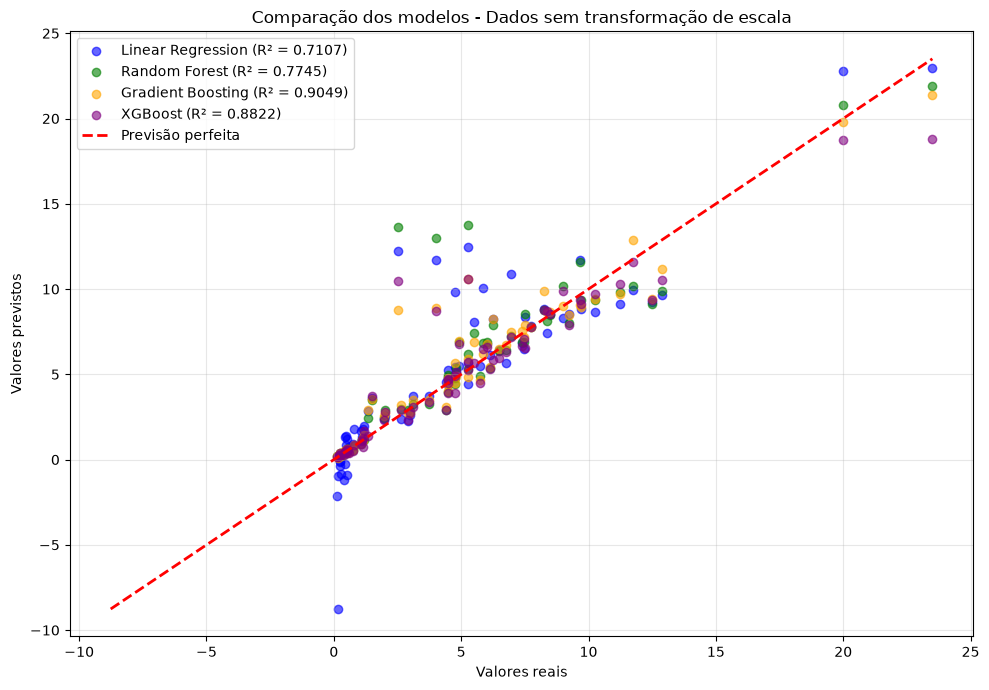

In [61]:
# Gráfico
plt.figure(figsize=(8, 6))

models = [pred_lr, pred_rf, pred_gb, pred_xgb]

nomes = ['Linear Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost']
cores = ['blue', 'green', 'orange', 'purple']

plt.figure(figsize=(10, 7))

for pred, nome, cor in zip(models, nomes, cores):
    r2 = r2_score(y_test, pred)

    plt.scatter(
        y_test,
        pred,
        color=cor,
        alpha=0.6,
        label=f'{nome} (R² = {r2:.4f})'
    )

# Linha de previsão perfeita
limite_min = min(y_test.min(), *(p.min() for p in models))
limite_max = max(y_test.max(), *(p.max() for p in models))

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    'r--',
    linewidth=2,
    label='Previsão perfeita'
)

plt.xlabel('Valores reais')
plt.ylabel('Valores previstos')
plt.title('Comparação dos modelos - Dados sem transformação de escala')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### **Plotagem Normalização**

<Figure size 800x600 with 0 Axes>

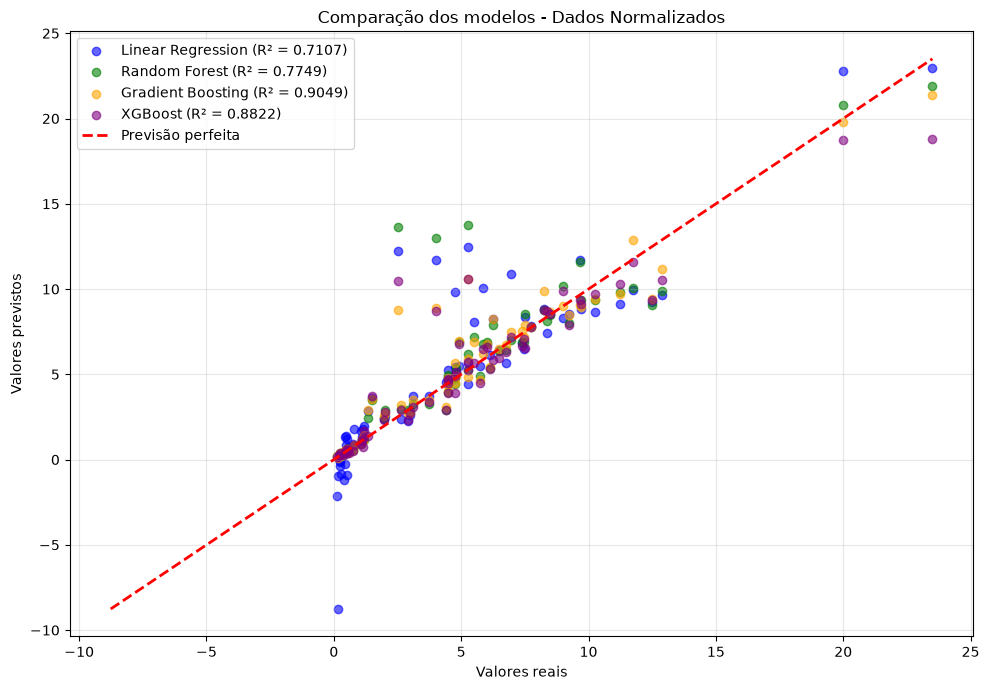

In [62]:
# Gráfico
plt.figure(figsize=(8, 6))

models = [pred_lr_norm, pred_rf_norm, pred_gb_norm, pred_xgb_norm]

nomes = ['Linear Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost']
cores = ['blue', 'green', 'orange', 'purple']

plt.figure(figsize=(10, 7))

for pred, nome, cor in zip(models, nomes, cores):
    r2 = r2_score(y_test, pred)

    plt.scatter(
        y_test,
        pred,
        color=cor,
        alpha=0.6,
        label=f'{nome} (R² = {r2:.4f})'
    )

# Linha de previsão perfeita
limite_min = min(y_test.min(), *(p.min() for p in models))
limite_max = max(y_test.max(), *(p.max() for p in models))

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    'r--',
    linewidth=2,
    label='Previsão perfeita'
)

plt.xlabel('Valores reais')
plt.ylabel('Valores previstos')
plt.title('Comparação dos modelos - Dados Normalizados')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### **Plotagem Padronização**

<Figure size 800x600 with 0 Axes>

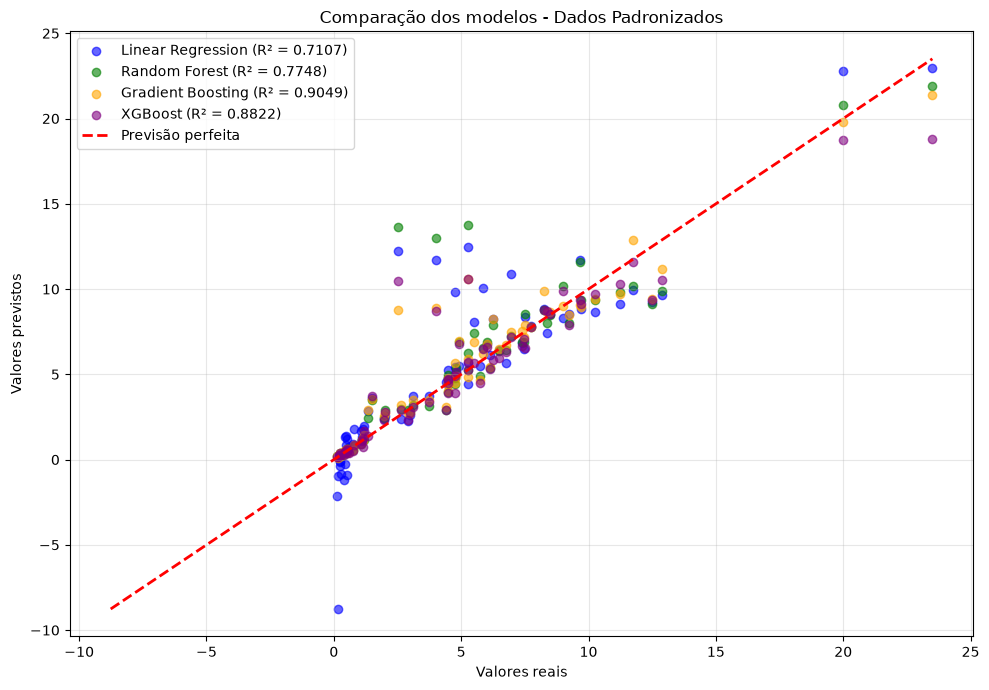

In [63]:
# Gráfico
plt.figure(figsize=(8, 6))

models = [pred_lr_std, pred_rf_std, pred_gb_std, pred_xgb_std]

nomes = ['Linear Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost']
cores = ['blue', 'green', 'orange', 'purple']

plt.figure(figsize=(10, 7))

for pred, nome, cor in zip(models, nomes, cores):
    r2 = r2_score(y_test, pred)

    plt.scatter(
        y_test,
        pred,
        color=cor,
        alpha=0.6,
        label=f'{nome} (R² = {r2:.4f})'
    )

# Linha de previsão perfeita
limite_min = min(y_test.min(), *(p.min() for p in models))
limite_max = max(y_test.max(), *(p.max() for p in models))

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    'r--',
    linewidth=2,
    label='Previsão perfeita'
)

plt.xlabel('Valores reais')
plt.ylabel('Valores previstos')
plt.title('Comparação dos modelos - Dados Padronizados')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **Resultados e Insights**

### 🧪 Comparativo de Pré-processamento: Original vs. Normalização vs. Padronização

Para medir o impacto real da escala dos dados em diferentes famílias de algoritmos, os quatro modelos foram retreinados e reavaliados em três cenários, mantendo **exatamente a mesma divisão treino/teste** e as **mesmas sementes aleatórias**:

1. **Dados Originais** (sem transformação de escala)
2. **Normalização** (`MinMaxScaler` — reescala para o intervalo `[0, 1]`)
3. **Padronização** (`StandardScaler` — média `0` e desvio padrão `1`)

| Modelo | Cenário | MAE ↓ | MAPE (%) ↓ | R² Score ↑ |
| :--- | :--- | :---: | :---: | :---: |
| **Gradient Boosting (GB)** | Original | 0.7260 | 23.05% | 0.9049 |
| | Normalizado | 0.7261 | 23.09% | 0.9049 |
| | Padronizado | 0.7263 | 23.07% | 0.9049 |
| **XGBoost (XGB)** | Original | 0.7460 | 21.61% | 0.8822 |
| | Normalizado | 0.7460 | 21.61% | 0.8822 |
| | Padronizado | 0.7460 | 21.61% | 0.8822 |
| **Random Forest (RF)** | Original | 0.9406 | 26.56% | 0.7745 |
| | Normalizado | 0.9355 | 26.31% | 0.7749 |
| | Padronizado | 0.9369 | 26.44% | 0.7748 |
| **Linear Regression (LR)** | Original | 1.3939 | 164.25% | 0.7107 |
| | Normalizado | 1.3939 | 164.25% | 0.7107 |
| | Padronizado | 1.3939 | 164.25% | 0.7107 |

**Amplitude máxima entre os três cenários:**

| Modelo | Δ MAE | Δ R² | Veredito |
| :--- | :---: | :---: | :--- |
| Linear Regression | `0.000000` | `0.000000` | Idêntico até a 6ª casa decimal |
| XGBoost | `0.000000` | `0.000000` | Idêntico até a 6ª casa decimal |
| Gradient Boosting | `0.000262` | `0.000054` | Ruído numérico (0,04% do MAE) |
| Random Forest | `0.005080` | `0.000368` | Ruído numérico (0,54% do MAE) |

### 💡 Análise Crítica e Conclusões

* **O experimento mostra que a escala é irrelevante para os quatro modelos deste projeto.** Nenhum deles apresentou variação que não seja atribuível a ruído de ponto flutuante. Esse é o resultado correto e esperado — e vale registrar que ele **só aparece depois de corrigir o ajuste do scaler no conjunto de teste**. 

* **Modelos baseados em árvores não se beneficiam de escala:** Algoritmos como *Gradient Boosting*, *XGBoost* e *Random Forest* realizam partições baseadas em regras de corte (`>` ou `<`), sendo naturalmente invariantes à escala das variáveis. Tanto o `MinMaxScaler` quanto o `StandardScaler` são transformações afins de inclinação positiva, portanto **monotônicas crescentes**: preservam a ordem. As diferenças residuais de GB e RF (4ª–5ª casa decimal) vêm de desempates entre cortes de ganho numericamente igual, que podem se resolver de forma diferente após o reescalonamento — não de qualquer mudança no poder preditivo.

* **Por que a Regressão Linear também é invariante — e por que isso contraria a intuição comum.** Existe a ideia difundida de que "modelos lineares precisam de padronização". Isso é verdade para modelos **regularizados** (Ridge, Lasso, ElasticNet), onde a penalidade `α·||β||` compara coeficientes de grandezas diferentes, e para otimizadores por **descida de gradiente**, cuja convergência depende do condicionamento das escalas. A `LinearRegression` do Scikit-learn **não é nenhum dos dois casos**: ela resolve o problema de mínimos quadrados analiticamente, por decomposição em valores singulares (SVD). Como uma transformação afim das colunas **não altera o subespaço gerado por** `[1, X]`, a projeção ortogonal de `y` sobre esse subespaço é a mesma. Os **coeficientes mudam**, a **previsão não muda**. Daí o resultado idêntico até a 6ª casa decimal nas três tabelas.

* **Consequência prática:** padronizar ou normalizar neste pipeline **não traz ganho de desempenho**. O valor de ter executado o experimento é **diagnóstico**, não otimização: ele produz a evidência empírica de que a escolha de escala não é uma alavanca a ser ajustada aqui, direcionando o esforço de melhoria para onde há retorno real (ajuste de hiperparâmetros e validação cruzada).

* **Decisão Final:** mantemos os **dados na escala original** com o **Gradient Boosting Regressor** (`MAE = 0.7260`, `MAPE = 23.05%`, `R² = 0.9049`). Como as três escalas são equivalentes em desempenho, a escala original é a reportada por manter as métricas na unidade do negócio (lakhs), preservando a interpretabilidade direta do MAE.

## **Persistência**

In [64]:
# Salvando o modelo para implantação
joblib.dump(gb, 'model_gb_veiculos.pk')
print('Modelo Salvo com Sucesso.')

Modelo Salvo com Sucesso.
